# Sneha Singh
## DATA 266 — Homework 11
CLIP: Caption–Image Similarity and Zero-Shot CIFAR-10

This notebook loads CLIP, compares one caption to CIFAR-10 images (100 per class), then runs zero-shot classification on the CIFAR-10 test set and reports per-class accuracy with a confusion matrix.


In [1]:
# Step 0: Libraries & Student Parameters
import os
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# last 4 of my SJSUid - 0670
SEED = 670
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SID4 = 670
SLICE = 670
HP_ID = 4
CLS_A = 0
CLS_B = 5

IMGS_PER_CLASS = 100
CAPTION = "a photo of a dog"
CLIP_NAME = "openai/clip-vit-base-patch32"
BATCH = 64

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("SID4: %04d" % SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID, "(reported only)")
print("CLS_A:", CLS_A, "CLS_B:", CLS_B)
print("device:", device)
print("torch:", torch.__version__)


SID4: 0670
SEED: 670
SLICE: 670
HP_ID: 4 (reported only)
CLS_A: 0 CLS_B: 5
device: mps
torch: 2.14.0


HP_ID is reported only. Part 1 compares one caption to many CIFAR-10 images. Part 2 is zero-shot classification on the CIFAR-10 test set.


## 1. Load CLIP

I load `openai/clip-vit-base-patch32` with the matching processor. CLIP maps text and images into one embedding space, so cosine similarity between a caption and an image is meaningful.


In [2]:
# load CLIP model and processor
model = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(CLIP_NAME)
print("model:", CLIP_NAME)
print("parameters:", sum(p.numel() for p in model.parameters()))


model: openai/clip-vit-base-patch32
parameters: 151277313


## 2. Caption–image similarity (Part A)

Caption: **"a photo of a dog"**.

I take 100 images from each CIFAR-10 class (1,000 images total). For every image I compute a normalized CLIP image embedding, compare it to the normalized caption embedding with cosine similarity, then plot the mean score per class and the top matches.


train: 50000 test: 10000
similarity images: 1000 (100 per class)
caption embedding shape: (1, 512)
scored 64/1000
scored 320/1000
scored 576/1000
scored 832/1000
scoring seconds: 8.4
airplane     mean sim=0.2037  n=100
automobile   mean sim=0.1996  n=100
bird         mean sim=0.2270  n=100
cat          mean sim=0.2398  n=100
deer         mean sim=0.2337  n=100
dog          mean sim=0.2603  n=100
frog         mean sim=0.2295  n=100
horse        mean sim=0.2210  n=100
ship         mean sim=0.1948  n=100
truck        mean sim=0.1963  n=100
highest mean class: dog (0.2603)


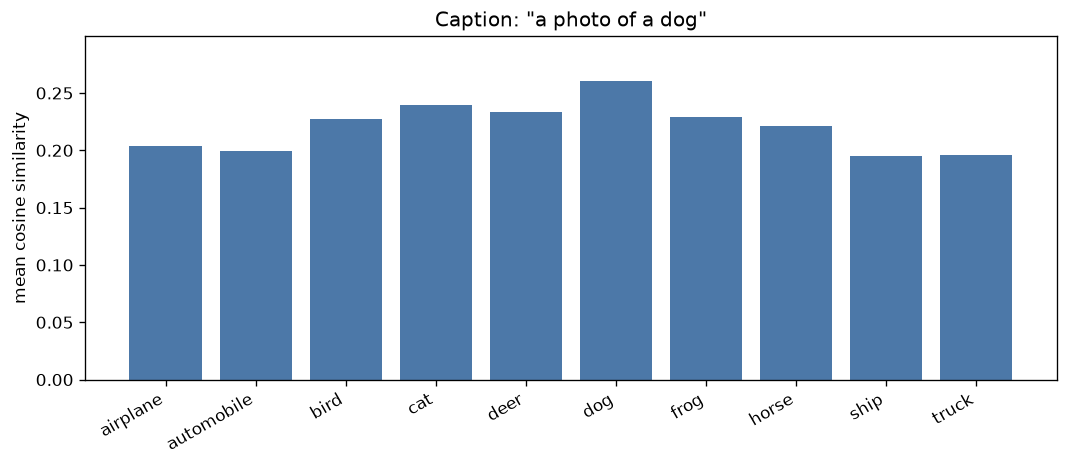

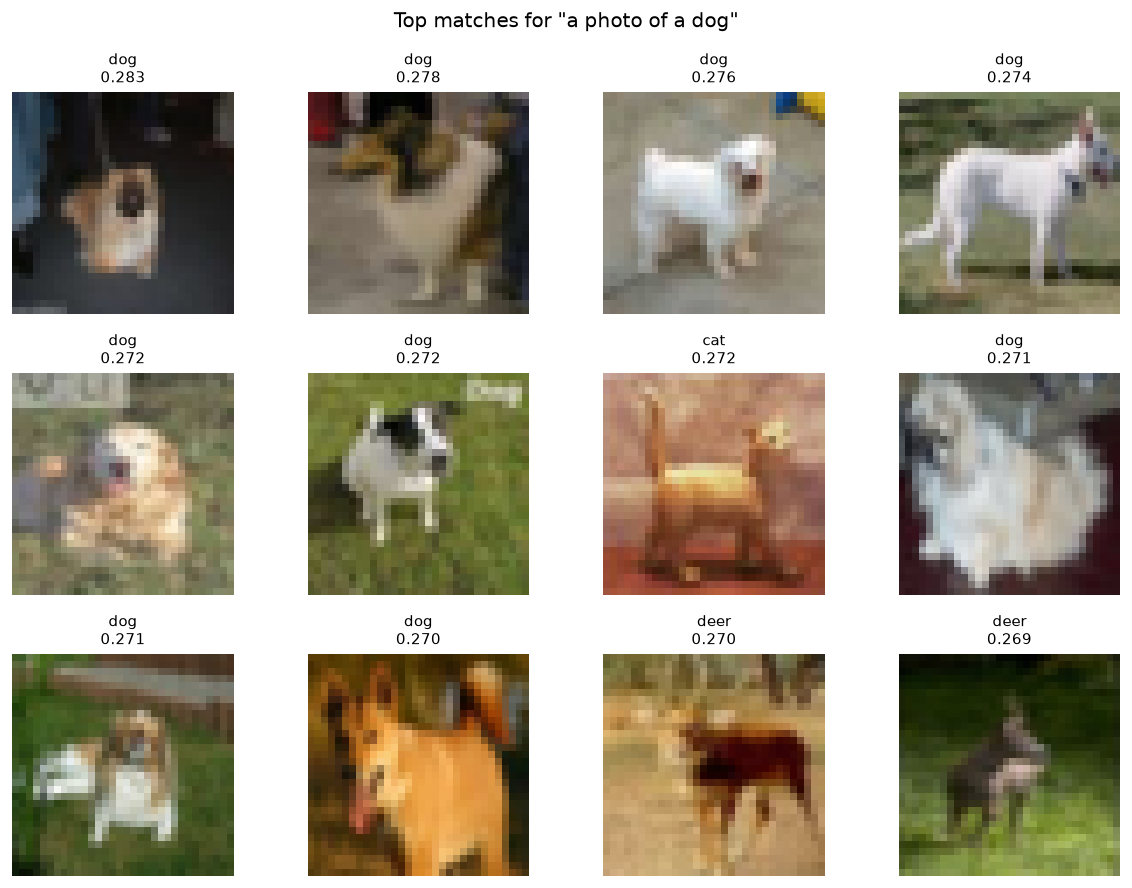

In [3]:
# CIFAR-10 class names and a balanced 100-per-class subset
CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

# keep raw PIL images for the CLIP processor
cifar_train = datasets.CIFAR10("./data", train=True, download=True)
cifar_test = datasets.CIFAR10("./data", train=False, download=True)
print("train:", len(cifar_train), "test:", len(cifar_test))

rng = np.random.default_rng(SEED)
sim_indices = []
for class_id in range(10):
    idxs = [i for i, y in enumerate(cifar_train.targets) if y == class_id]
    chosen = rng.choice(idxs, size=IMGS_PER_CLASS, replace=False)
    sim_indices.extend(chosen.tolist())
print("similarity images:", len(sim_indices), f"({IMGS_PER_CLASS} per class)")

def _as_feat(out):
    # newer transformers return BaseModelOutputWithPooling; pooler_output is projected
    if hasattr(out, "pooler_output"):
        return out.pooler_output
    return out

@torch.no_grad()
def embed_texts(texts):
    inputs = processor(text=texts, return_tensors="pt", padding=True).to(device)
    feats = _as_feat(model.get_text_features(**inputs))
    return F.normalize(feats, dim=-1)

@torch.no_grad()
def embed_images(pil_images):
    inputs = processor(images=pil_images, return_tensors="pt").to(device)
    feats = _as_feat(model.get_image_features(**inputs))
    return F.normalize(feats, dim=-1)

text_emb = embed_texts([CAPTION])
print("caption embedding shape:", tuple(text_emb.shape))

# score every selected image against the caption
records = []
t0 = time.perf_counter()
for start in range(0, len(sim_indices), BATCH):
    batch_idx = sim_indices[start:start + BATCH]
    images = [cifar_train[i][0] for i in batch_idx]
    labels = [int(cifar_train[i][1]) for i in batch_idx]
    img_emb = embed_images(images)
    sims = (img_emb @ text_emb.T).squeeze(-1).detach().cpu().numpy()
    for i, lab, score in zip(batch_idx, labels, sims):
        records.append({"index": i, "label": lab, "score": float(score), "image": cifar_train[i][0]})
    if start % (BATCH * 4) == 0:
        print(f"scored {min(start + BATCH, len(sim_indices))}/{len(sim_indices)}")
print(f"scoring seconds: {time.perf_counter() - t0:.1f}")

# mean similarity by class
class_means = []
for class_id, name in enumerate(CIFAR10_CLASSES):
    vals = [r["score"] for r in records if r["label"] == class_id]
    class_means.append(float(np.mean(vals)))
    print(f"{name:12s} mean sim={np.mean(vals):.4f}  n={len(vals)}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(CIFAR10_CLASSES, class_means, color="#4C78A8")
ax.set_ylabel("mean cosine similarity")
ax.set_title(f'Caption: "{CAPTION}"')
ax.set_ylim(0, max(class_means) * 1.15)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/caption_class_similarity.png", dpi=150)
plt.show()

# top-12 images by similarity
top = sorted(records, key=lambda r: r["score"], reverse=True)[:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for ax, row in zip(axes.ravel(), top):
    ax.imshow(row["image"])
    ax.set_title(f'{CIFAR10_CLASSES[row["label"]]}\n{row["score"]:.3f}', fontsize=9)
    ax.axis("off")
plt.suptitle(f'Top matches for "{CAPTION}"', fontsize=12)
plt.tight_layout()
plt.savefig("figures/caption_top_matches.png", dpi=150)
plt.show()

best_class = CIFAR10_CLASSES[int(np.argmax(class_means))]
print("highest mean class:", best_class, f"({max(class_means):.4f})")


## 3. Zero-shot CIFAR-10 classification (Part B)

I classify the full CIFAR-10 test set with prompts `a photo of a {class}`. The predicted class is the prompt with the highest cosine similarity. I report overall accuracy, per-class accuracy, and a confusion matrix.


class text embedding shape: (10, 512)
- a photo of a airplane
- a photo of a automobile
- a photo of a bird
- a photo of a cat
- a photo of a deer
- a photo of a dog
- a photo of a frog
- a photo of a horse
- a photo of a ship
- a photo of a truck
classified 64/10000
classified 1344/10000
classified 2624/10000
classified 3904/10000
classified 5184/10000
classified 6464/10000
classified 7744/10000
classified 9024/10000
zero-shot seconds: 80.0
overall accuracy: 0.8880

per-class accuracy:
airplane     0.9010  (n=1000)
automobile   0.9760  (n=1000)
bird         0.8880  (n=1000)
cat          0.8600  (n=1000)
deer         0.7650  (n=1000)
dog          0.8840  (n=1000)
frog         0.7740  (n=1000)
horse        0.9760  (n=1000)
ship         0.9550  (n=1000)
truck        0.9010  (n=1000)
wrote outputs/metrics.json


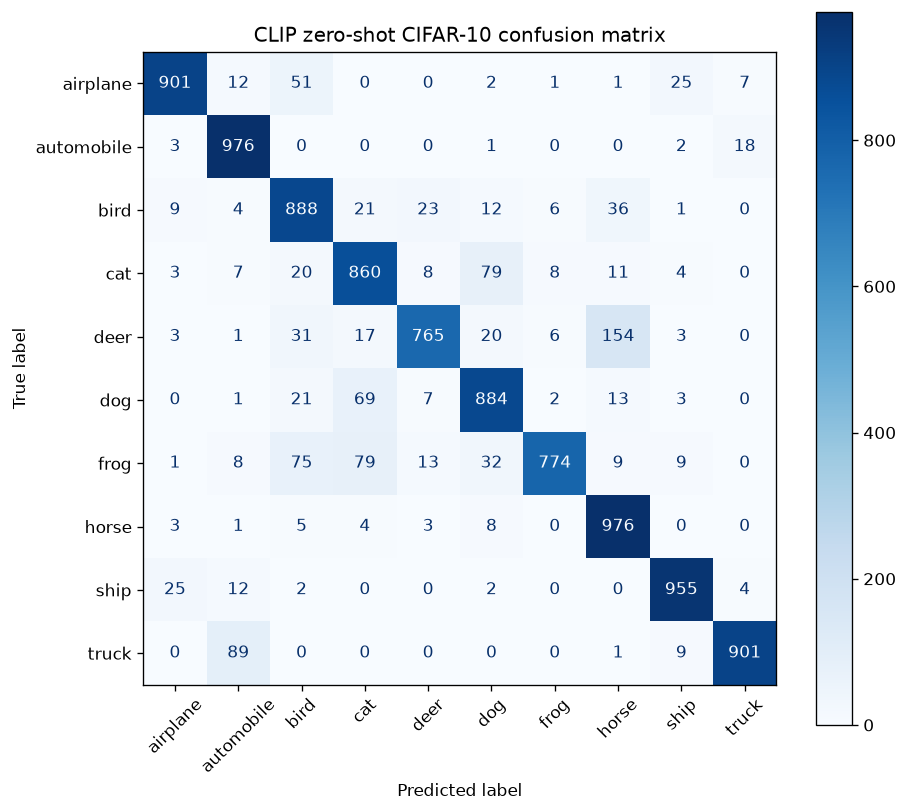

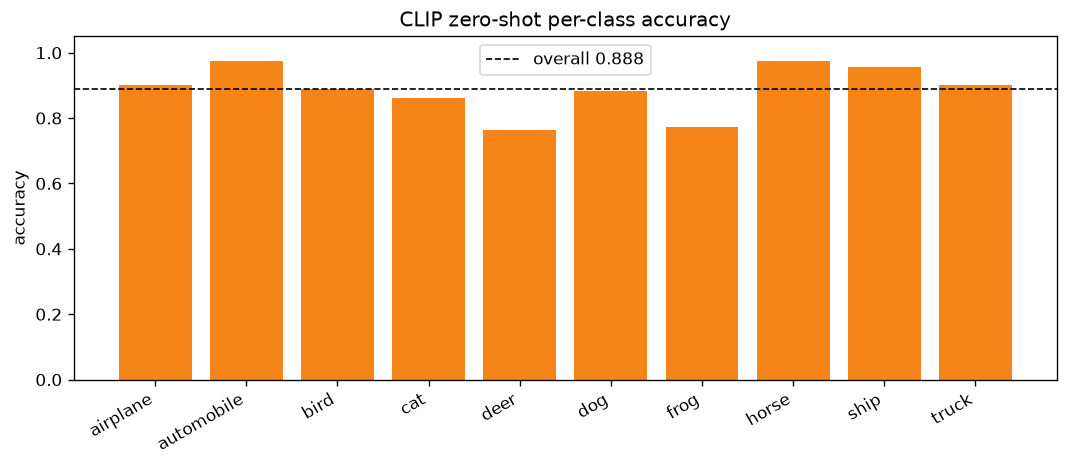

In [4]:
# zero-shot prompts and text embeddings for all 10 classes
prompts = [f"a photo of a {name}" for name in CIFAR10_CLASSES]
class_text_emb = embed_texts(prompts)
print("class text embedding shape:", tuple(class_text_emb.shape))
for p in prompts:
    print("-", p)

@torch.no_grad()
def predict_batch(pil_images):
    img_emb = embed_images(pil_images)
    logits = img_emb @ class_text_emb.T
    return logits.argmax(dim=-1).detach().cpu().numpy()

y_true = []
y_pred = []
t0 = time.perf_counter()
for start in range(0, len(cifar_test), BATCH):
    end = min(start + BATCH, len(cifar_test))
    images = [cifar_test[i][0] for i in range(start, end)]
    labels = [int(cifar_test[i][1]) for i in range(start, end)]
    preds = predict_batch(images)
    y_true.extend(labels)
    y_pred.extend(preds.tolist())
    if start % (BATCH * 20) == 0:
        print(f"classified {end}/{len(cifar_test)}")
print(f"zero-shot seconds: {time.perf_counter() - t0:.1f}")

y_true = np.array(y_true)
y_pred = np.array(y_pred)
overall = float((y_true == y_pred).mean())
print(f"overall accuracy: {overall:.4f}")

per_class = []
print("\nper-class accuracy:")
for class_id, name in enumerate(CIFAR10_CLASSES):
    mask = y_true == class_id
    acc = float((y_pred[mask] == class_id).mean())
    per_class.append(acc)
    print(f"{name:12s} {acc:.4f}  (n={mask.sum()})")

cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CIFAR10_CLASSES)
disp.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=45)
ax.set_title("CLIP zero-shot CIFAR-10 confusion matrix")
plt.tight_layout()
plt.savefig("figures/zeroshot_confusion_matrix.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(CIFAR10_CLASSES, per_class, color="#F58518")
ax.axhline(overall, color="black", linestyle="--", linewidth=1, label=f"overall {overall:.3f}")
ax.set_ylabel("accuracy")
ax.set_title("CLIP zero-shot per-class accuracy")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/zeroshot_per_class_accuracy.png", dpi=150)
plt.show()

# save numbers for the report
import json
payload = {
    "caption": CAPTION,
    "imgs_per_class": IMGS_PER_CLASS,
    "class_mean_similarity": {n: float(v) for n, v in zip(CIFAR10_CLASSES, class_means)},
    "best_similarity_class": best_class,
    "overall_accuracy": overall,
    "per_class_accuracy": {n: float(v) for n, v in zip(CIFAR10_CLASSES, per_class)},
    "confusion_matrix": cm.tolist(),
}
with open("outputs/metrics.json", "w") as f:
    json.dump(payload, f, indent=2)
print("wrote outputs/metrics.json")


## 4. Discussion

Caption **"a photo of a dog"** had the highest mean cosine similarity on the dog class (0.260), then cat (0.240) and other animals. Vehicles (ship, truck, automobile) scored lowest. That matches the caption: the top-12 gallery is mostly dogs.

Zero-shot CIFAR-10 test accuracy was **88.8%**. Automobile and horse were strongest (97.6% each). Deer was weakest (76.5%), mostly confused with horse. Cat and dog also swap with each other in the confusion matrix, which is expected for similar animals at 32×32 resolution.
